**Detección de URLs de phishing con aprendizaje automático**
---

## Contenido
1. Importación de librerías
2. Carga y exploración del dataset
3. Preprocesamiento
4. Selección de características (RFECV)
5. Red neuronal
6. Random Forest
7. SVM
8. KNN
9. Naive Bayes
10. Conclusiones

## Descripción del proyecto
El phishing consiste en engañar al usuario mediante una copia de una página web legítima o a través de comunicaciones por email o mensajería en las que se suplanta la identidad de la empresa original y se le solicita al usuario la introducción de su información personal.

Este proyecto implementa una estrategia de anti-phishing que identifica si la URL de una página web es phishing. Se entrenan y comparan cinco clasificadores binarios: red neuronal, Random Forest, SVM, KNN y Naive Bayes. Las métricas de comparación son accuracy y F1.

## Dataset
[Phishing Dataset for Machine Learning](https://www.kaggle.com/datasets/shashwatwork/phishing-dataset-for-machine-learning?resource=download) (Kaggle). Contiene 10.000 páginas web (5.000 phishing y 5.000 legítimas) con 48 características extraídas de la URL y del código fuente HTML de cada página.

## 1. Importación de librerías
Primero, se importan las librerías necesarias.

In [1]:
%matplotlib inline

# Manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Red neuronal (PyTorch)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Preprocesamiento y selección de características
from sklearn import preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    RepeatedStratifiedKFold,
    GridSearchCV,
)
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline

# Modelos de clasificación
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Métricas
from sklearn.metrics import accuracy_score, f1_score

Se fija una semilla para que los resultados sean reproducibles y se crea el diccionario `results`, donde se irán guardando las métricas de cada modelo para compararlos al final.

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Métricas de cada modelo sobre su conjunto de test (se llena en cada sección)
results = {}

## 2. Carga y exploración del dataset
Se importa el dataset.

In [3]:
# El archivo debe estar en la misma carpeta que el notebook
df = pd.read_csv("Phishing_Legitimate_full.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  10000 non-null  int64  
 1   NumDots                             10000 non-null  int64  
 2   SubdomainLevel                      10000 non-null  int64  
 3   PathLevel                           10000 non-null  int64  
 4   UrlLength                           10000 non-null  int64  
 5   NumDash                             10000 non-null  int64  
 6   NumDashInHostname                   10000 non-null  int64  
 7   AtSymbol                            10000 non-null  int64  
 8   TildeSymbol                         10000 non-null  int64  
 9   NumUnderscore                       10000 non-null  int64  
 10  NumPercent                          10000 non-null  int64  
 11  NumQueryComponents                  10000 non-null  i

In [5]:
df['CLASS_LABEL'].value_counts()

CLASS_LABEL
1    5000
0    5000
Name: count, dtype: int64

El dataset tiene 50 columnas. La columna objetivo es `CLASS_LABEL`, que toma valores 0 y 1 e indica si la URL de la página es phishing (1) o legítima (0). Las clases están balanceadas: 5.000 muestras de cada una.

## 3. Preprocesamiento

Se eliminan las columnas `SubdomainLevelRT`, `UrlLengthRT`, `PctExtResourceUrlsRT`, `AbnormalExtFormActionR`, `ExtMetaScriptLinkRT` y `PctExtNullSelfRedirectHyperlinksRT`, ya que son información repetida en el dataset. De igual manera, se elimina `id`, porque es una columna de tipo índice que no brinda información, y `HttpsInHostname`, porque tiene un único valor en toda la columna.

In [6]:
# Eliminación de columnas redundantes, de índice o con un único valor
df = df.drop(columns=['HttpsInHostname', 'id', 'SubdomainLevelRT', 'UrlLengthRT',
                      'PctExtResourceUrlsRT', 'AbnormalExtFormActionR',
                      'ExtMetaScriptLinkRT', 'PctExtNullSelfRedirectHyperlinksRT'])

Se separa el dataset en características (`X`) y variable objetivo (`y`).

In [7]:
X = df.drop('CLASS_LABEL', axis=1)
y = df['CLASS_LABEL']

## 4. Selección de características (RFECV)

Se usará Recursive Feature Elimination with Cross-Validation (RFECV), que utiliza validación cruzada para determinar automáticamente el número óptimo de características a seleccionar. Esto se hace para reducir la dimensionalidad de los datos, eliminando iterativamente las características menos relevantes.

Se crea una instancia de RFECV utilizando un `DecisionTreeClassifier` como estimador:

In [8]:
rfe = RFECV(estimator=DecisionTreeClassifier(random_state=SEED))
model = DecisionTreeClassifier(random_state=SEED)

# Pipeline que encadena el selector de características (rfe) y el clasificador (model)
pipeline = Pipeline(steps=[('s', rfe), ('m', model)])

Se evalúa el rendimiento del modelo utilizando `RepeatedStratifiedKFold` con 10 divisiones (`n_splits=10`) y 3 repeticiones (`n_repeats=3`):

In [9]:
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
n_scores = cross_val_score(pipeline, X, y, scoring='accuracy', cv=cv, n_jobs=-1, error_score='raise')

# Exactitud media y desviación estándar
print('Accuracy: %.3f (%.3f)' % (np.mean(n_scores), np.std(n_scores)))

Accuracy: 0.964 (0.007)


Se imprimen las columnas que RFECV seleccionó como las mejores características.

In [10]:
pipeline.fit(X, y)                         # Entrenar el pipeline (incluye RFECV)
rfe = pipeline.named_steps['s']            # Obtener el objeto RFECV del pipeline
selected_columns = X.columns[rfe.support_] # Obtener las columnas seleccionadas

print(f"Número de características seleccionadas: {len(selected_columns)}")
print("Columnas seleccionadas:")
for column in selected_columns:
    print(column)

Número de características seleccionadas: 23
Columnas seleccionadas:
NumDots
PathLevel
UrlLength
NumDash
NumDashInHostname
NumUnderscore
NumPercent
NumQueryComponents
NumNumericChars
NoHttps
HostnameLength
PathLength
QueryLength
NumSensitiveWords
PctExtHyperlinks
PctExtResourceUrls
InsecureForms
RelativeFormAction
ExtFormAction
PctNullSelfRedirectHyperlinks
FrequentDomainNameMismatch
SubmitInfoToEmail
IframeOrFrame


Se puede observar que, por medio de RFECV, se disminuyó el número de columnas a 23, quedando con las siguientes características:

| Característica | Tipo | Descripción |
|---|---|---|
| `NumDots` | Discreta | Número de puntos en la URL. |
| `PathLevel` | Discreta | Profundidad de la ruta en la URL de la página web. |
| `UrlLength` | Discreta | Número total de caracteres en la URL. |
| `NumDash` | Discreta | Número de "-" en la URL de la página web. |
| `NumDashInHostname` | Discreta | Número de "-" en el hostname de la URL. |
| `NumUnderscore` | Discreta | Número de "_" en la URL. |
| `NumPercent` | Discreta | Número de "%" en la URL. |
| `NumQueryComponents` | Discreta | Número de queries en la URL. |
| `NumNumericChars` | Discreta | Número de caracteres numéricos en la URL. |
| `NoHttps` | Binaria | Indica si la URL no usa el protocolo HTTPS. |
| `HostnameLength` | Discreta | Cantidad de caracteres en la parte del nombre del host de la URL. |
| `PathLength` | Discreta | Total de caracteres en la ruta de la URL. |
| `QueryLength` | Discreta | Número total de caracteres en la parte de la consulta de la URL. |
| `NumSensitiveWords` | Discreta | Cantidad de palabras confidenciales (p. ej., "secure", "account", "webscr", "login", "ebayisapi", "signin", "banking", "confirm") en la URL de la página web. |
| `PctExtHyperlinks` | Continua | Porcentaje de hipervínculos externos en el código fuente HTML de la URL. |
| `PctExtResourceUrls` | Continua | Porcentaje de URLs de recursos externos en el código fuente HTML de la página web. |
| `InsecureForms` | Binaria | Indica si el atributo de acción del formulario contiene una URL sin protocolo HTTPS. |
| `RelativeFormAction` | Binaria | Indica si el atributo de acción del formulario contiene una URL relativa. |
| `ExtFormAction` | Binaria | Indica si el atributo de acción del formulario contiene una URL de un dominio externo. |
| `PctNullSelfRedirectHyperlinks` | Continua | Porcentaje de hipervínculos que contienen un valor vacío, un valor de autoredireccionamiento como "#", la URL de la página web actual o algún valor anormal como "file://E:/". |
| `FrequentDomainNameMismatch` | Binaria | Indica si el dominio más frecuente en los enlaces del código fuente HTML es distinto del dominio de la URL de la página. |
| `SubmitInfoToEmail` | Binaria | Indica si el código fuente HTML contiene la función `mailto`. |
| `IframeOrFrame` | Binaria | Indica si se usa `iframe` o `frame` en el código fuente HTML. |

Se establece un nuevo dataframe con solo estas características (más la variable objetivo):

In [11]:
x = df[list(selected_columns) + ['CLASS_LABEL']]
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   NumDots                        10000 non-null  int64  
 1   PathLevel                      10000 non-null  int64  
 2   UrlLength                      10000 non-null  int64  
 3   NumDash                        10000 non-null  int64  
 4   NumDashInHostname              10000 non-null  int64  
 5   NumUnderscore                  10000 non-null  int64  
 6   NumPercent                     10000 non-null  int64  
 7   NumQueryComponents             10000 non-null  int64  
 8   NumNumericChars                10000 non-null  int64  
 9   NoHttps                        10000 non-null  int64  
 10  HostnameLength                 10000 non-null  int64  
 11  PathLength                     10000 non-null  int64  
 12  QueryLength                    10000 non-null  int64  
 13

## 5. Red neuronal

Se separa el dataset en train (81%), validation (9%) y test (10%).

In [12]:
# 10% para test; del 90% restante, 10% para validación
x_train_val, x_test = train_test_split(x, test_size=0.1, random_state=42)
x_train, x_val = train_test_split(x_train_val, test_size=0.1, random_state=42)

Se define la clase `MyDataset` para convertir los datos de los atributos y la variable objetivo en parejas ordenadas de tensores y así alimentar la red neuronal.

In [13]:
class MyDataset(Dataset):
    """Dataset de PyTorch a partir de un DataFrame.

    Separa la columna objetivo y convierte atributos y etiquetas a tensores float32.
    """

    def __init__(self, df, target_column):
        y = df[target_column].values
        X = df.drop(target_column, axis=1).values
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

Se usa la clase `MyDataset` para convertir cada conjunto definido anteriormente a tensores. En este caso, se envían como argumentos el respectivo conjunto y la variable objetivo.

In [14]:
train_sec = MyDataset(x_train, 'CLASS_LABEL')
test_sec = MyDataset(x_test, 'CLASS_LABEL')
val_sec = MyDataset(x_val, 'CLASS_LABEL')

Se definen los dataloaders para procesar los datos y alimentar la red neuronal por lotes: `batch_size = 3` para train y validation, y `batch_size = 1` para test. Los datos de entrenamiento se mezclan en cada época (`shuffle=True`).

In [15]:
train_data = DataLoader(
    train_sec,
    batch_size=3,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

test_data = DataLoader(
    test_sec,
    batch_size=1,
    shuffle=False,
)

val_data = DataLoader(
    val_sec,
    batch_size=3,
    shuffle=False,
)

Se crea la clase `Net`, que define la arquitectura de la red neuronal: una capa de entrada con una neurona por característica (23), dos capas ocultas con 15 y 3 nodos, y una neurona de salida. Como función de activación se usó la función sigmoide, que en la capa de salida entrega una probabilidad entre 0 y 1. En esta sección los datos de entrada se usan sin estandarizar; estandarizarlos es una posible mejora.

In [16]:
class Net(nn.Module):
    """Red neuronal feed-forward: n_features -> 15 -> 3 -> 1, con activación sigmoide en todas las capas."""

    def __init__(self, n_features):
        super().__init__()
        self.fc1 = nn.Linear(n_features, 15)
        self.fc2 = nn.Linear(15, 3)
        self.fc3 = nn.Linear(3, 1)

    def forward(self, x):
        # Forward pass
        x = torch.sigmoid(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

Se define el modelo, el optimizador (Adam) y la función de costo. Se usó un learning rate de 0.001. Como función de costo se usó `BCELoss` (Binary Cross Entropy), ya que es un problema de clasificación binaria y se adapta mejor a este tipo de problemas.

In [17]:
model = Net(n_features=x.shape[1] - 1)
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)
criterion = nn.BCELoss()

Ahora se entrena el modelo con `num_epochs = 20`. Se guarda en `proyecto.pt` el modelo con menor error de validación.

In [18]:
def train_model(model, optimizer, loss_module, train_loader, valid_loader, num_epochs=20):
    """Entrena el modelo y guarda en 'proyecto.pt' los pesos con menor error de validación.

    Args:
        model: red neuronal a entrenar.
        optimizer: optimizador de PyTorch.
        loss_module: función de costo.
        train_loader: DataLoader de entrenamiento.
        valid_loader: DataLoader de validación.
        num_epochs: número de épocas.
    """

    valid_loss_min = np.inf  # Se busca el menor error de validación, por eso se inicializa como 'infinito'

    for epoch in range(num_epochs):
        # ---- Entrenamiento ----
        model.train()
        train_loss = 0.0
        for data, target in train_loader:
            # Se reinician los gradientes
            optimizer.zero_grad()
            # Forward pass: calcular la salida para los datos de entrada
            preds = model(data).squeeze(dim=1)
            # Costo del lote
            loss = loss_module(preds, target)
            # Backpropagation: cálculo de gradientes
            loss.backward()
            # Actualizar los parámetros
            optimizer.step()
            # Acumular el costo a lo largo de los lotes
            train_loss += loss.item() * data.size(0)
        train_loss = train_loss / len(train_loader.dataset)

        # ---- Validación ----
        model.eval()
        valid_loss = 0.0
        with torch.no_grad():
            for data, target in valid_loader:
                preds = model(data).squeeze(dim=1)
                valid_loss += loss_module(preds, target).item() * data.size(0)
        valid_loss = valid_loss / len(valid_loader.dataset)

        # Estadísticas de entrenamiento y validación
        print('Epoch: {} \tTraining Loss: {:.6f} \tValidation Loss: {:.6f}'.format(
            epoch + 1, train_loss, valid_loss))

        # Se guarda el modelo con el menor error de validación
        if valid_loss <= valid_loss_min:
            print('Validation loss decreased ({:.6f} --> {:.6f}).  Saving model ...'.format(
                valid_loss_min, valid_loss))
            torch.save(model.state_dict(), 'proyecto.pt')
            valid_loss_min = valid_loss

In [19]:
train_model(model, optimizer, criterion, train_data, val_data)

Epoch: 1 	Training Loss: 0.552842 	Validation Loss: 0.368084
Validation loss decreased (inf --> 0.368084).  Saving model ...
Epoch: 2 	Training Loss: 0.281389 	Validation Loss: 0.238749
Validation loss decreased (0.368084 --> 0.238749).  Saving model ...
Epoch: 3 	Training Loss: 0.214996 	Validation Loss: 0.203997
Validation loss decreased (0.238749 --> 0.203997).  Saving model ...
Epoch: 4 	Training Loss: 0.195172 	Validation Loss: 0.191235
Validation loss decreased (0.203997 --> 0.191235).  Saving model ...
Epoch: 5 	Training Loss: 0.180950 	Validation Loss: 0.202455
Epoch: 6 	Training Loss: 0.177053 	Validation Loss: 0.181599
Validation loss decreased (0.191235 --> 0.181599).  Saving model ...
Epoch: 7 	Training Loss: 0.170726 	Validation Loss: 0.182457
Epoch: 8 	Training Loss: 0.168583 	Validation Loss: 0.170030
Validation loss decreased (0.181599 --> 0.170030).  Saving model ...
Epoch: 9 	Training Loss: 0.167102 	Validation Loss: 0.170262
Epoch: 10 	Training Loss: 0.164188 	Valida

Se carga el modelo guardado con menor error de validación y se calcula el test loss.

In [20]:
model.load_state_dict(torch.load('proyecto.pt'))
model.eval()

test_loss = 0.0
with torch.no_grad():
    for data, target in test_data:
        output = model(data).squeeze(dim=1)
        loss = criterion(output, target)
        test_loss += loss.item() * data.size(0)
test_loss = test_loss / len(test_data.dataset)
print('Test Loss: {:.6f}\n'.format(test_loss))

Test Loss: 0.152821



Se calcula el accuracy sobre el conjunto de test.

In [21]:
# Predicciones sobre el conjunto de test (umbral de 0.5)
preds, labels_test = [], []
with torch.no_grad():
    for inputs, labels in test_data:
        outputs = model(inputs).squeeze(dim=1)
        preds.append(torch.round(outputs))
        labels_test.append(labels)
y_pred_nn = torch.cat(preds)
y_true_nn = torch.cat(labels_test)

accuracy_nn = (y_pred_nn == y_true_nn).float().mean().item()
print('El accuracy del test de la red es: %.2f %%' % (100 * accuracy_nn))

El accuracy del test de la red es: 94.00 %


Se usará la métrica F1 para evaluar el modelo, ya que la idea del modelo es determinar cuándo una URL es phishing, y se debe lograr un equilibrio entre precision y sensitivity (recall). Se deben clasificar correctamente las URLs de páginas web que sean phishing (sensitivity) y, al mismo tiempo, evitar la clasificación incorrecta de URLs legítimas como phishing (precision).

In [22]:
true_positives = ((y_pred_nn == 1) & (y_true_nn == 1)).sum().item()
false_positives = ((y_pred_nn == 1) & (y_true_nn == 0)).sum().item()
false_negatives = ((y_pred_nn == 0) & (y_true_nn == 1)).sum().item()

precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)

print('Precision:', precision)
print('Recall:', recall)

Precision: 0.937246963562753
Recall: 0.9410569105691057


In [23]:
# F1: media armónica entre precision y recall
f1_nn = 2 * (precision * recall) / (precision + recall)
print('F1:', f1_nn)

results['Red neuronal'] = {'Partición (train / test)': '81% / 10% (+ 9% validación)',
                           'Accuracy': accuracy_nn, 'F1': f1_nn}

F1: 0.9391480730223123


El accuracy (94,3%) y el F1 (0,942) muestran que la red neuronal tiene un buen rendimiento: clasifica correctamente la gran mayoría de las URLs y mantiene un buen equilibrio entre precision y recall. No se exploraron todas las posibles variaciones de arquitectura e hiperparámetros, por lo que podría mejorar con más ajuste.

## 6. Random Forest

Ahora se entrenará un modelo con Random Forest. Se separa la columna objetivo y se divide el dataset en train y test con una proporción de 70% y 30%.

In [24]:
X = x.drop('CLASS_LABEL', axis=1)
y = x['CLASS_LABEL']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

Se usa `RandomForestClassifier` de sklearn y se entrena el modelo con el conjunto de train.

In [25]:
rf = RandomForestClassifier(random_state=SEED)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Se realizan predicciones del modelo sobre los datos de prueba.

In [26]:
y_pred = rf.predict(X_test)

Se comparan las etiquetas verdaderas (`y_test`) con las etiquetas predichas (`y_pred`) y se calculan el accuracy (porcentaje de muestras en las que las etiquetas predichas coinciden con las verdaderas) y el F1 del modelo.

In [27]:
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("F1-score:", f1)

results['Random Forest'] = {'Partición (train / test)': '70% / 30%', 'Accuracy': accuracy, 'F1': f1}

Accuracy: 0.9783333333333334
F1-score: 0.9785549323655559


Random Forest obtuvo un accuracy de 97,8% y un F1 de 0,979, el mejor rendimiento de los cinco modelos. Al combinar varios árboles de decisión, el modelo captura bien las relaciones entre las características y reduce el sobreajuste.

## 7. SVM

Se divide el dataset en train y test con una proporción de 70% y 30%, y se estandarizan los datos para que todas las características estén en la misma escala. El escalador se ajusta únicamente con los datos de train y luego se aplica a train y a test.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

Se buscan los mejores parámetros `C` y `gamma` para el clasificador SVC utilizando Grid Search con validación cruzada (5 folds) y `roc_auc` como métrica.

In [29]:
num_features = np.size(X_train, axis=1)
param_grid = [
    {'C': [1, 10, 100, 1000],
     'gamma': [1/num_features, 1, 0.1, 0.01, 0.001, 0.0001],
     'kernel': ['rbf']},
]
optimal_params = GridSearchCV(
    SVC(),
    param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=0,
    n_jobs=-1,
)
optimal_params.fit(X_train, y_train)
print(optimal_params.best_params_)

{'C': 10, 'gamma': 0.043478260869565216, 'kernel': 'rbf'}


Se entrena un clasificador de Máquina de Soporte Vectorial con los parámetros encontrados anteriormente.

In [30]:
clf = SVC(**optimal_params.best_params_)
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.043478260869565216
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Se predicen las etiquetas del conjunto de prueba con el clasificador `clf` y se comparan con las etiquetas verdaderas `y_test` para calcular el accuracy y el F1 score con las funciones de sklearn.

In [31]:
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("F1 score:", f1)

results['SVM'] = {'Partición (train / test)': '70% / 30%', 'Accuracy': accuracy, 'F1': f1}

Accuracy: 0.9583333333333334
F1 score: 0.9588951002959553


El SVM con kernel RBF y los parámetros encontrados con Grid Search (`C=10`, `gamma≈0.043`) obtuvo un accuracy de 95,8% y un F1 de 0,959, un rendimiento alto aunque inferior al de Random Forest.

## 8. KNN

Se separa el dataset en train y test, en una proporción de 70% y 30%. Como KNN se basa en distancias, las características se estandarizan con un escalador ajustado solo con los datos de train.

In [32]:
# Se separa la columna objetivo
X = x.drop('CLASS_LABEL', axis=1)
y = x['CLASS_LABEL']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0, test_size=0.3, shuffle=True)

scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Se importa el clasificador `KNeighborsClassifier` de sklearn con el nombre `knn` y se usa k=3. También se entrena el clasificador con los datos de entrenamiento.

In [34]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


Se calculan el accuracy y el F1 con las funciones de sklearn.

In [35]:
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("F1 score:", f1)

results['KNN (k=3)'] = {'Partición (train / test)': '70% / 30%', 'Accuracy': accuracy, 'F1': f1}

Accuracy: 0.9463333333333334
F1 score: 0.9469871583799803


Ahora se entrenan clasificadores KNN con diferentes valores de k (de 1 a 99) y se visualiza el cambio del accuracy entre ellos.

In [36]:
scores = []
for i in range(1, 100):
    knn_i = KNeighborsClassifier(n_neighbors=i)
    knn_i.fit(X_train, y_train)
    scores.append(knn_i.score(X_test, y_test))

print('k con mayor accuracy: %d (accuracy = %.4f)' % (np.argmax(scores) + 1, max(scores)))

k con mayor accuracy: 5 (accuracy = 0.9473)


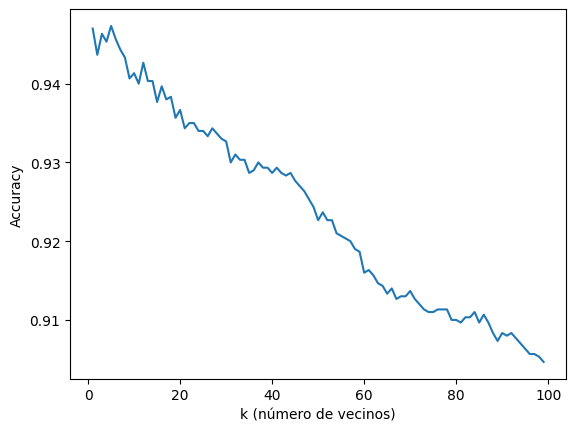

In [37]:
plt.plot(range(1, 100), scores)
plt.xlabel("k (número de vecinos)")
plt.ylabel("Accuracy")
plt.show()

Con k=3, KNN obtuvo un accuracy de 94,6% y un F1 de 0,947. El accuracy se mantiene entre 94% y 95% para valores pequeños de k (el máximo, 94,7%, se alcanza con k=1 y k=5) y disminuye de forma sostenida a medida que k aumenta, hasta cerca de 90% con k=99. Por eso se usa k=3, un valor pequeño con buen rendimiento.

## 9. Naive Bayes

Se separa el dataset en train y test, en una proporción de 67% y 33%.

In [38]:
# Se separa la columna objetivo
X = x.drop('CLASS_LABEL', axis=1)
y = x['CLASS_LABEL']

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=125)

Se entrena el clasificador (`GaussianNB`) en el conjunto de entrenamiento utilizando los hiperparámetros por defecto.

In [40]:
nb = GaussianNB()
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[3332.,3368.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.131e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](23,)","['NumDots','PathLevel','UrlLength',...,'FrequentDomainNameMismatch', 'SubmitInfoToEmail','IframeOrFrame']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,23
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 23)","[[ 2.06, 2.83,72.96,..., 0.02, 0.25, 0.45], [ 2.85, 3.72,68.05,..., 0.41, 0.01, 0.24]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 23)","[[ 1. , 3.27, 975.66,..., 0.02, 0.19, 0.25], [ 2.45, 3.16,1271.73,..., 0.24, 0.01, 0.18]]"


Se usarán el accuracy y la métrica F1 para determinar el rendimiento del modelo.

In [41]:
y_pred = nb.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("F1 Score:", f1)

results['Naive Bayes'] = {'Partición (train / test)': '67% / 33%', 'Accuracy': accuracy, 'F1': f1}

Accuracy: 0.8575757575757575
F1 Score: 0.8422818791946308


Naive Bayes obtuvo el menor rendimiento (accuracy de 85,8% y F1 de 0,842). Este modelo asume que las características son independientes entre sí, y en este dataset varias de ellas están correlacionadas (por ejemplo, las que miden longitudes de partes de la URL), como se observa en la matriz de correlación.

Se visualiza la matriz de correlación entre las características para analizar el resultado.

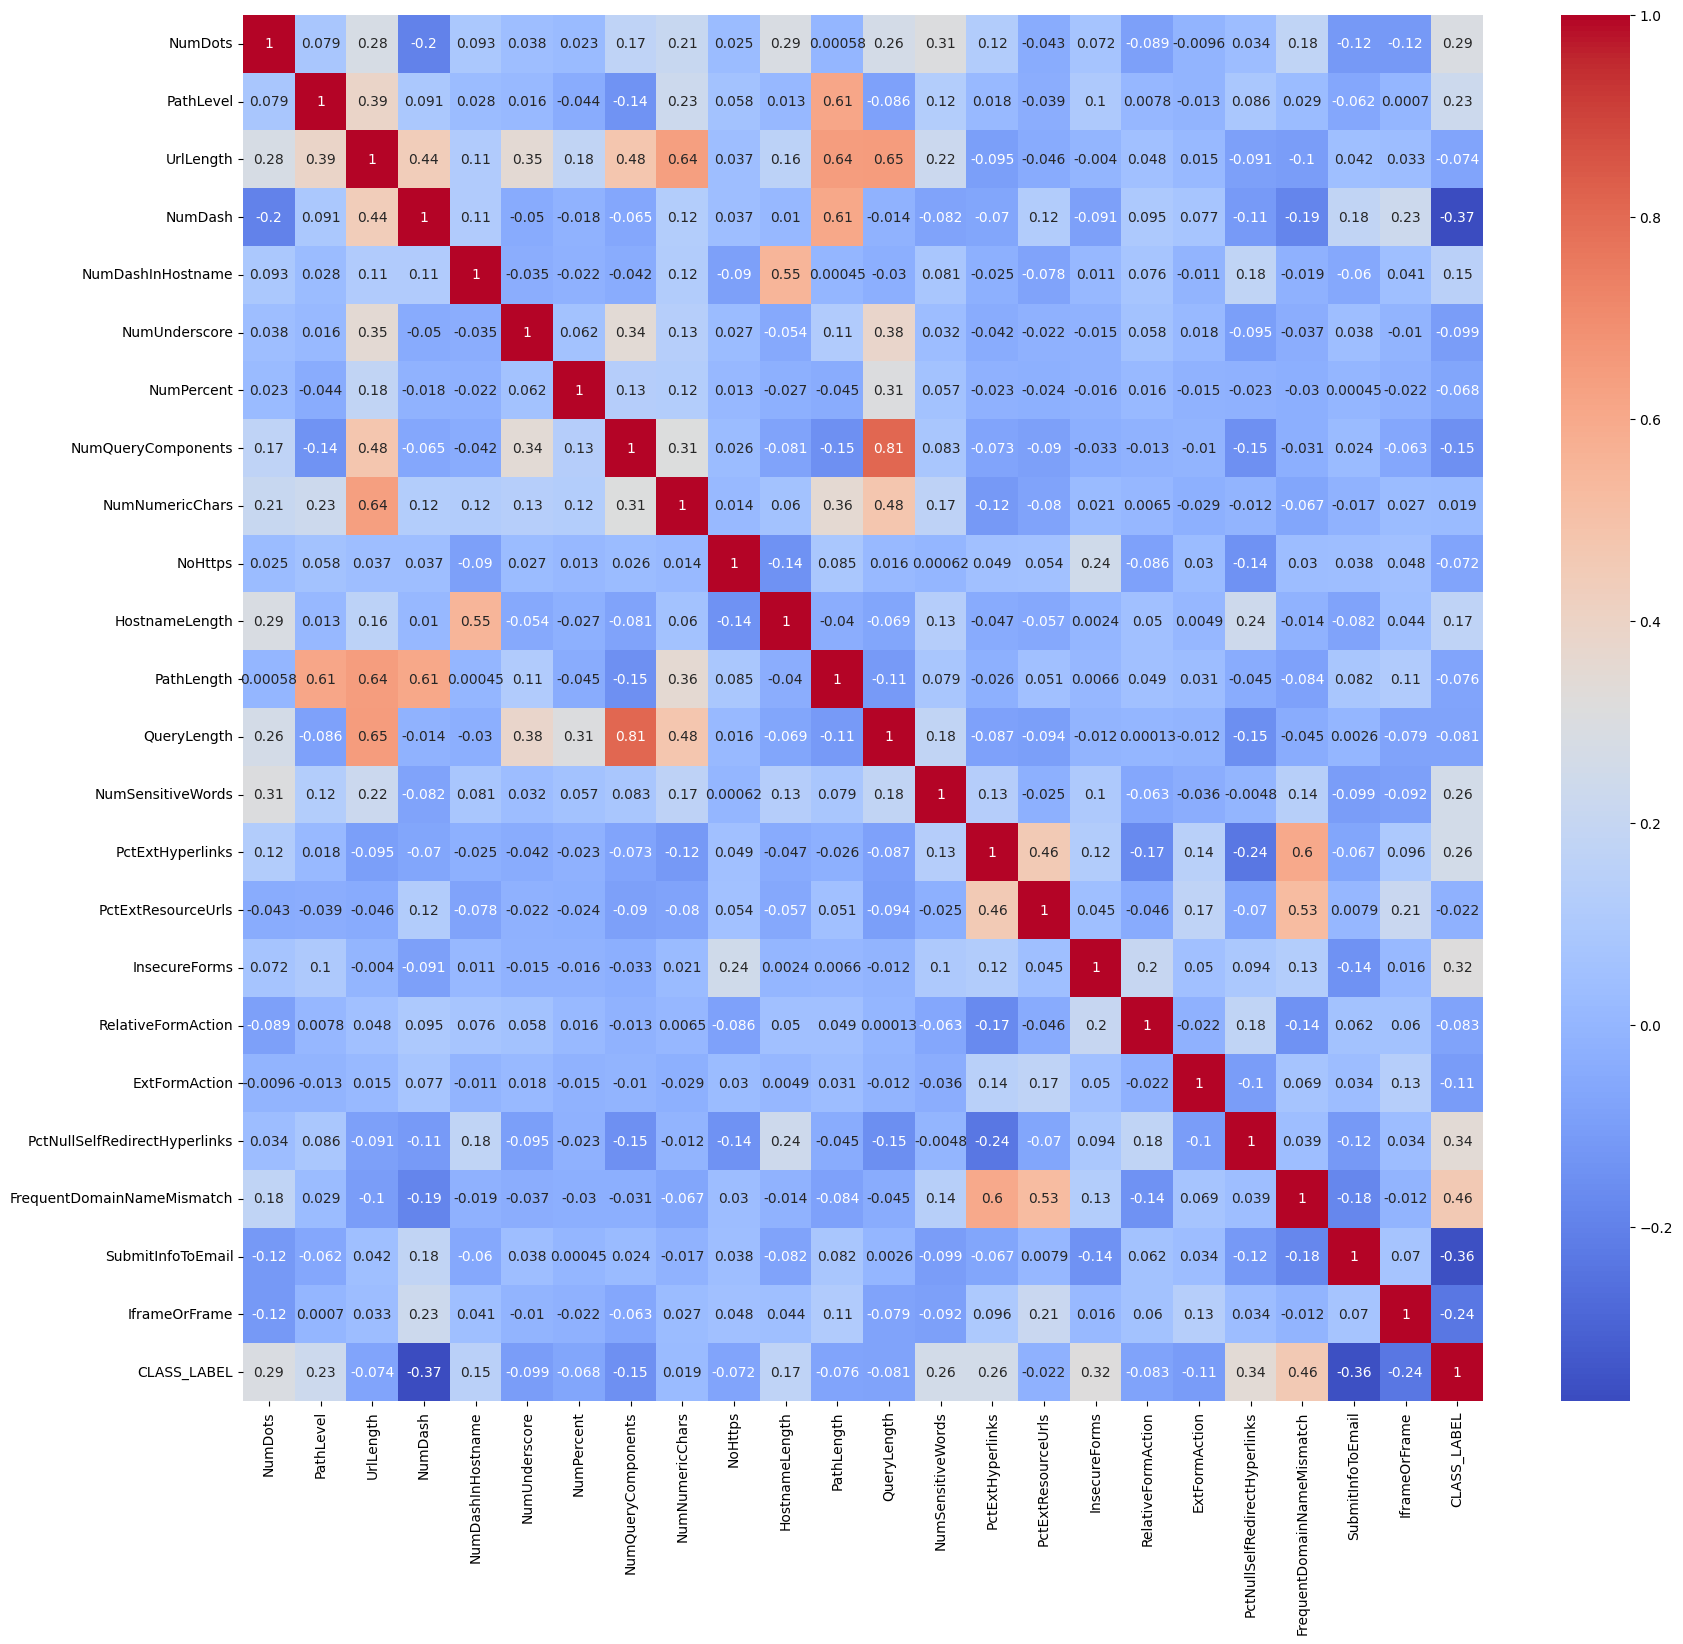

In [42]:
matriz_correlacion = x.corr()
plt.figure(figsize=(20, 18))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm')
plt.show()

Se observa correlación moderada a alta entre varias características (por ejemplo, `NumQueryComponents` y `QueryLength`, con cerca de 0,8). Esto incumple el supuesto de independencia de Naive Bayes y es una posible explicación de su menor rendimiento frente a los demás modelos.

## 10. Conclusiones

Resumen de resultados en el conjunto de prueba de cada modelo:

In [43]:
resumen = pd.DataFrame(results).T
resumen[['Accuracy', 'F1']] = resumen[['Accuracy', 'F1']].round(3)
resumen

,Partición (train / test),Accuracy,F1
Red neuronal,81% / 10% (+ 9% validación),0.94,0.939148
Random Forest,70% / 30%,0.978333,0.978555
SVM,70% / 30%,0.958333,0.958895
KNN (k=3),70% / 30%,0.946333,0.946987
Naive Bayes,67% / 33%,0.857576,0.842282


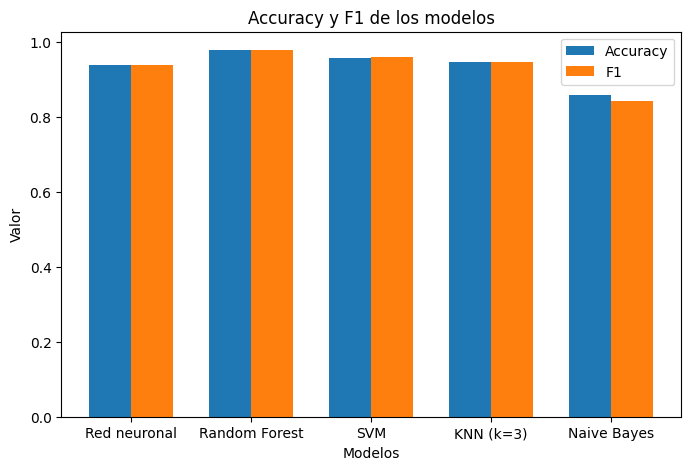

In [44]:
# Gráfica comparativa a partir de los resultados calculados en cada sección
model_names = list(results.keys())
accuracy_values = [results[m]['Accuracy'] for m in model_names]
f1_values = [results[m]['F1'] for m in model_names]

bar_width = 0.35
r1 = np.arange(len(model_names))
r2 = r1 + bar_width

plt.figure(figsize=(8, 5))
plt.bar(r1, accuracy_values, width=bar_width, label='Accuracy')
plt.bar(r2, f1_values, width=bar_width, label='F1')
plt.xlabel("Modelos")
plt.ylabel("Valor")
plt.title("Accuracy y F1 de los modelos")
plt.xticks(r1 + bar_width / 2, model_names)
plt.legend()
plt.show()

**Random Forest fue el mejor modelo.** Las 23 características mezclan conteos (`NumDots`, `NumDash`), longitudes (`UrlLength`, `PathLength`), porcentajes y variables binarias (`NoHttps`, `InsecureForms`), todas en escalas muy distintas. Random forest trabaja con umbrales sobre cada variable, por lo que no depende de la escala y capta bien interacciones no lineales, por ejemplo una URL larga combinada con palabras sensibles y formularios inseguros. Además, al promediar muchos árboles reduce la varianza y el sobreajuste de un árbol individual. También es posible que RFECV lo favorezca, porque la selección de características se hizo con un árbol de decisión como estimador.

**SVM (95.8%) quedó en segundo lugar.** El SVM separa las dos clases con una frontera suave y continua. Random Forest, en cambio, separa los casos con muchas reglas que se ajustan mejor a los casos puntuales. Algunas URLs de phishing se parecen mucho a las legítimas (y al revés), y en esos casos las reglas de Random Forest se adaptan mejor que una sola frontera suave. Por eso el SVM tiene buen rednimiento, pero no es el mejor modelo.

**KNN (94.6%) y la red neuronal (94.3%) tuvieron un rendimiento similar.**
- *KNN:* clasifica según los vecinos más cercanos y da el mismo peso a las 23 características, incluidas las menos informativas, que agregan ruido a la distancia. El accuracy se mantiene entre 94% y 95% con k pequeño y baja de forma sostenida al aumentar k, hasta cerca de 90% con k=99. Esto indica que la información útil está en vecindarios locales y que un k grande suaviza demasiado la frontera. 
- *Red neuronal:* el error de entrenamiento (≈0.150) y el de validación (≈0.166) son parecidos, así que el modelo no está memorizando los datos de entrenamiento (no hay sobreajuste). Aun así, su accuracy (94.3%) es menor que el de Random Forest y SVM, lo que sugiere que la red aprende menos de lo que podría. La red es pequeña (la capa intermedia tiene solo 3 nodos), se entrenó solo 20 épocas y las entradas no están estandarizadas, lo que dificulta el aprendizaje con activación sigmoide. Con más ajuste, podría acercarse a SVM o Random Forest.


**Naive Bayes fue el menos preciso (85.8%).** Este modelo asume que las características son independientes entre sí, y en este dataset varias no lo son: por ejemplo, `NumQueryComponents` y `QueryLength` tienen una correlación cercana a 0.8, y `UrlLength` está correlacionada con `PathLength` y `NumNumericChars`. Además, `GaussianNB` supone distribuciones normales, y muchas variables son binarias. El F1 (0.842) por debajo del accuracy sugiere además que los errores no se reparten de forma pareja entre las dos clases.

## Conclusiones

- Los modelos que capturan relaciones no lineales entre características (Random Forest, SVM, KNN y red neuronal) superan el 94% de accuracy, mientras que el que asume independencia (Naive Bayes) queda en 85.8%. Esto indica que las características se relacionan entre sí y que esa estructura es relevante para detectar phishing.
- Random Forest es la mejor opción para este problema: tiene el mayor accuracy y F1, no requiere estandarizar los datos y es sencillo de ajustar.
- Con solo 23 de las 48 características originales se obtienen buenos resultados, lo que permite detectar phishing con información de la URL y del código HTML de la página, sin necesidad de todo el conjunto.
- Los modelos se evaluaron con particiones distintas (ver tabla de la sección 10), por lo que las diferencias pequeñas, como entre KNN y la red neuronal, deben interpretarse con cautela.
- **Posibles mejoras:** usar la misma partición para todos los modelos (o validación cruzada), estandarizar las entradas de la red y ajustar su arquitectura e hiperparámetros, y repetir la selección de características con otros estimadores para evitar favorecer a los modelos basados en árboles.